# CareGraph — Symptom-Based Doctor Specialty Recommendation

This notebook keeps the recommendation workflow in **one Jupyter notebook** rather than splitting it across Python modules.

## Workflow
1. Load and inspect the supplied CSV/XLSX files.
2. Standardize symptom and disease names.
3. Build a symptom-to-disease classifier from `Original_Dataset.csv`.
4. Inspect and validate the disease-to-specialty mapping in `Doctor_Versus_Disease.csv`.
5. Recommend a possible specialty from a list of **confirmed, normalized patient symptoms**.
6. Evaluate the classifier and export the trained model and cleaned mapping.

> **Safety note:** This is a student prototype, not a clinically validated system. A model prediction is not a diagnosis. The supplied mappings include questionable/inconsistent labels, so review them with reliable medical guidance before using recommendations for real people. Severe or emergency symptoms should bypass model-based recommendations and prompt urgent medical care.


## 0. Install dependencies

Run this cell in the notebook environment if required. If you are using the project's existing `.venv`, install Jupyter and the listed libraries into that environment first.

In [1]:
%pip install pandas numpy scikit-learn matplotlib openpyxl joblib
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 1. Locate and load the datasets

Put these files in the same folder as this notebook, or in a `Data/` or `data/` subfolder:
- `Original_Dataset.csv`
- `Doctor_Versus_Disease.csv`
- `Disease_Description.csv`
- `Doctor_Specialist.csv`
- `Symptom_Weights.csv`
- `Specialist.xlsx` (optional comparison dataset)

The loader searches common project folders. If it cannot find a file, set `DATA_DIR` manually.

In [2]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd

# If needed, replace None with a folder path, e.g. Path(r"C:\\Users\\Shreyas\\Desktop\\CareGraph\\SymptomExtraction")
DATA_DIR = "C:\\Users\\Shreyas\\Desktop\\CareGraph\\Data"

if DATA_DIR is not None:
    DATA_DIR = Path(DATA_DIR)
else:
    candidates = [Path.cwd(), Path.cwd() / "Data", Path.cwd() / "data",
                  Path.cwd().parent / "Data", Path.cwd().parent / "data"]
    DATA_DIR = next((p for p in candidates if (p / "Original_Dataset.csv").exists()), Path.cwd())

print("Notebook working directory:", Path.cwd())
print("Data directory:", DATA_DIR)

def find_file(filename, required=True):
    search_dirs = [DATA_DIR, Path.cwd(), Path.cwd() / "Data", Path.cwd() / "data"]
    for folder in search_dirs:
        candidate = folder / filename
        if candidate.exists():
            return candidate
    if required:
        raise FileNotFoundError(
            f"Could not find {filename}. Put it beside this notebook or in Data/ or data/, "
            "or set DATA_DIR in the cell above."
        )
    return None

def read_csv_flexible(path, **kwargs):
    # These supplied files have mixed encodings; try common Windows encodings too.
    last_error = None
    for encoding in ("utf-8-sig", "cp1252", "latin1"):
        try:
            return pd.read_csv(path, encoding=encoding, **kwargs)
        except UnicodeDecodeError as exc:
            last_error = exc
    raise last_error

original_path = find_file("Original_Dataset.csv")
mapping_path = find_file("Doctor_Versus_Disease.csv")
description_path = find_file("Disease_Description.csv", required=False)
specialists_path = find_file("Doctor_Specialist.csv", required=False)
weights_path = find_file("Symptom_Weights.csv", required=False)
specialist_xlsx_path = find_file("Specialist.xlsx", required=False)

original_raw = read_csv_flexible(original_path)
# The mapping file's first row is data, not a header. Read it with header=None.
mapping_raw = read_csv_flexible(mapping_path, header=None)
descriptions_raw = read_csv_flexible(description_path) if description_path else None
specialists_raw = read_csv_flexible(specialists_path, header=None) if specialists_path else None
weights_raw = read_csv_flexible(weights_path, header=None) if weights_path else None
direct_raw = pd.read_excel(specialist_xlsx_path) if specialist_xlsx_path else None

print("Original dataset:", original_raw.shape)
print("Disease-specialty mapping:", mapping_raw.shape)
print("Descriptions:", None if descriptions_raw is None else descriptions_raw.shape)
print("Specialist.xlsx:", None if direct_raw is None else direct_raw.shape)
display(original_raw.head())
display(mapping_raw.head())


Notebook working directory: c:\Users\Shreyas\Desktop\CareGraph\Recommendation
Data directory: C:\Users\Shreyas\Desktop\CareGraph\Data
Original dataset: (4920, 18)
Disease-specialty mapping: (41, 2)
Descriptions: (41, 2)
Specialist.xlsx: (4920, 133)


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,0,1
0,Drug Reaction,Allergist
1,Allergy,Allergist
2,Hypertension,Cardiologist
3,Heart attack,Cardiologist
4,Psoriasis,Dermatologist


## 2. Prepare symptom names and inspect dataset quality

The symptom names are normalized for whitespace and case consistency. This is a data-cleaning operation, not a medical synonym system. The vocabulary must still be aligned with your existing `SymptomNormalizer`.

`Symptom_Weights.csv` contains sequential identifiers; do not interpret those numbers as medically meaningful symptom weights.

In [3]:
def clean_label(value):
    if pd.isna(value):
        return ""
    value = str(value).replace("\\xa0", " ").strip().lower()
    value = re.sub(r"\\s+", " ", value)
    return value

def symptom_key(value):
    # Keep underscores and words; remove accidental surrounding/internal whitespace.
    value = clean_label(value)
    value = re.sub(r"\\s*_\\s*", "_", value)
    value = re.sub(r"_+", "_", value)
    return value

disease_col = "Disease"
symptom_cols = [c for c in original_raw.columns if str(c).startswith("Symptom_")]
if disease_col not in original_raw.columns or not symptom_cols:
    raise ValueError("Unexpected Original_Dataset.csv schema. Expected Disease and Symptom_1... columns.")

data = original_raw.copy()
data[disease_col] = data[disease_col].map(clean_label)
for col in symptom_cols:
    data[col] = data[col].map(symptom_key)

data[symptom_cols] = data[symptom_cols].replace("", np.nan)
disease_counts = data[disease_col].value_counts()

print(f"Rows: {len(data):,}")
print(f"Disease classes: {data[disease_col].nunique()}")
print(f"Symptom slots: {len(symptom_cols)}")
print("Missing disease labels:", int(data[disease_col].eq("").sum()))
print("Duplicate full rows:", int(data.duplicated().sum()))
print("Disease counts (top 10):")
display(disease_counts.head(10).to_frame("rows"))


Rows: 4,920
Disease classes: 41
Symptom slots: 17
Missing disease labels: 0
Duplicate full rows: 4616
Disease counts (top 10):


,rows
Disease,
fungal infection,120
allergy,120
gerd,120
chronic cholestasis,120
drug reaction,120
peptic ulcer diseae,120
aids,120
diabetes,120
gastroenteritis,120


## 3. Convert symptom lists into a binary feature matrix

Each canonical symptom becomes one feature:
- `1`: the symptom appears in the dataset row.
- `0`: the symptom does not appear in that row.

The input columns are sorted and deduplicated, so the model receives a consistent feature order. This is the same representation you will need to create from the output of your symptom extraction pipeline.

In [4]:
# Collect every distinct symptom in the training data.
symptom_vocabulary = sorted({
    symptom_key(value)
    for col in symptom_cols
    for value in data[col].dropna().tolist()
    if symptom_key(value)
})

def row_to_symptom_set(row):
    return {symptom_key(v) for v in row if pd.notna(v) and symptom_key(v)}

symptom_sets = data[symptom_cols].apply(row_to_symptom_set, axis=1)

X = pd.DataFrame(
    {symptom: symptom_sets.apply(lambda s, target=symptom: int(target in s))
     for symptom in symptom_vocabulary},
    index=data.index,
    dtype=np.uint8
)
y = data[disease_col].copy()

print("Feature matrix shape:", X.shape)
print("Unique symptom features:", len(symptom_vocabulary))
display(X.head())
print("Sample feature names:", symptom_vocabulary[:25])


Feature matrix shape: (4920, 131)
Unique symptom features: 131


,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,bladder_discomfort,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Sample feature names: ['abdominal_pain', 'abnormal_menstruation', 'acidity', 'acute_liver_failure', 'altered_sensorium', 'anxiety', 'back_pain', 'belly_pain', 'blackheads', 'bladder_discomfort', 'blister', 'blood_in_sputum', 'bloody_stool', 'blurred_and_distorted_vision', 'breathlessness', 'brittle_nails', 'bruising', 'burning_micturition', 'chest_pain', 'chills', 'cold_hands_and_feets', 'coma', 'congestion', 'constipation', 'continuous_feel_of_urine']


## 4. Train and evaluate a baseline disease classifier

This notebook uses a Random Forest baseline. It is a starting point, not a claim that Random Forest is the best model.

**Data-quality caution:** Public symptom/disease datasets may contain repeated or highly similar symptom patterns. A random stratified split can overestimate generalization when similar rows occur in both training and test sets. We report duplicate-pattern information and use a stratified split for an initial baseline; for a stronger evaluation, group identical symptom patterns together and inspect class coverage.

Unique symptom patterns: 304
Patterns repeated across rows: 304
Patterns associated with multiple disease labels: 0

Training samples: 3936
Testing samples: 984
Number of disease classes: 41

Training Logistic Regression...
Accuracy: 1.0000 | Macro F1: 1.0000 | Time: 1.13s

Training   "Linear SVM": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        StandardScaler(),
        LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    ),Random Forest...
Accuracy: 1.0000 | Macro F1: 1.0000 | Time: 2.76s

Training Extra Trees...
Accuracy: 1.0000 | Macro F1: 1.0000 | Time: 1.41s

Training Gradient Boosting...
Accuracy: 1.0000 | Macro F1: 1.0000 | Time: 54.91s

Training XGBoost...
XGBoost failed: Invalid classes inferred from unique values of `y`.  Expected: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40], got ['(vertigo) paroymsal  posi

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (sec)
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.13
1,"""Linear SVM"": make_pipeline( SimpleImputer(strategy=""most_frequent""), StandardScaler(), LinearSVC( class_weight=""balanced"", random_state=42, max_iter=10000 ) ),Random Forest",1.0000,1.0000,1.0000,1.0000,1.0000,2.76
2,Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,1.41
3,Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000,54.91
4,LightGBM,1.0000,1.0000,1.0000,1.0000,1.0000,5.35



BEST MODEL SELECTED
Model: Logistic Regression
Accuracy: 1.0000
Macro F1: 1.0000
Weighted F1: 1.0000


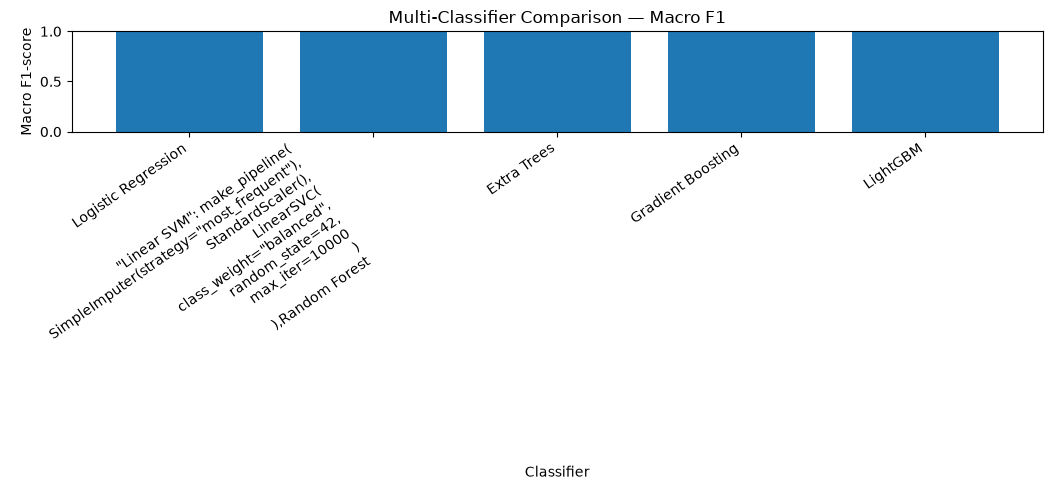


Classification Report: Logistic Regression

                                         precision    recall  f1-score   support

(vertigo) paroymsal  positional vertigo       1.00      1.00      1.00        24
                                   acne       1.00      1.00      1.00        24
                                   aids       1.00      1.00      1.00        24
                    alcoholic hepatitis       1.00      1.00      1.00        24
                                allergy       1.00      1.00      1.00        24
                              arthritis       1.00      1.00      1.00        24
                       bronchial asthma       1.00      1.00      1.00        24
                   cervical spondylosis       1.00      1.00      1.00        24
                            chicken pox       1.00      1.00      1.00        24
                    chronic cholestasis       1.00      1.00      1.00        24
                            common cold       1.00      1.00   

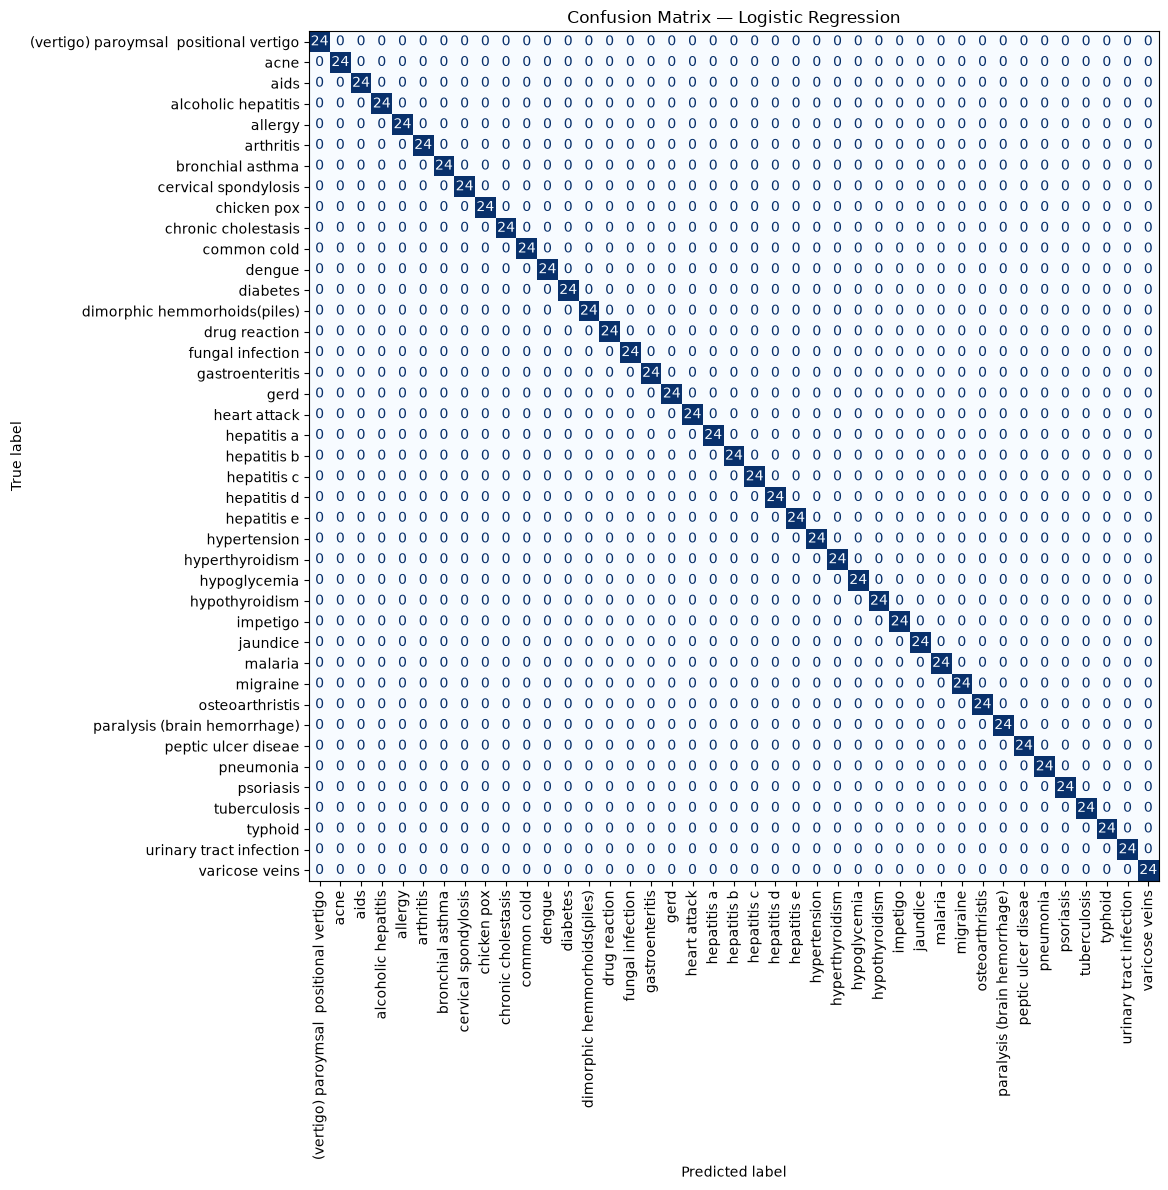


Comparison results saved to:
classifier_comparison_results.csv

Models that failed:
- XGBoost: Invalid classes inferred from unique values of `y`.  Expected: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40], got ['(vertigo) paroymsal  positional vertigo' 'acne' 'aids'
 'alcoholic hepatitis' 'allergy' 'arthritis' 'bronchial asthma'
 'cervical spondylosis' 'chicken pox' 'chronic cholestasis' 'common cold'
 'dengue' 'diabetes' 'dimorphic hemmorhoids(piles)' 'drug reaction'
 'fungal infection' 'gastroenteritis' 'gerd' 'heart attack' 'hepatitis a'
 'hepatitis b' 'hepatitis c' 'hepatitis d' 'hepatitis e' 'hypertension'
 'hyperthyroidism' 'hypoglycemia' 'hypothyroidism' 'impetigo' 'jaundice'
 'malaria' 'migraine' 'osteoarthristis' 'paralysis (brain hemorrhage)'
 'peptic ulcer diseae' 'pneumonia' 'psoriasis' 'tuberculosis' 'typhoid'
 'urinary tract infection' 'varicose veins']


In [5]:
import time
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. Check repeated and conflicting symptom patterns
# --------------------------------------------------

pattern_to_labels = {}

for idx, symptoms in enumerate(symptom_sets):
    pattern = tuple(sorted(symptoms))
    pattern_to_labels.setdefault(pattern, set()).add(y.iloc[idx])

conflicting_patterns = {
    pattern: labels
    for pattern, labels in pattern_to_labels.items()
    if len(labels) > 1
}

pattern_counts = pd.Series(
    [tuple(sorted(symptoms)) for symptoms in symptom_sets]
).value_counts()

print("Unique symptom patterns:", len(pattern_to_labels))
print("Patterns repeated across rows:", int((pattern_counts > 1).sum()))
print("Patterns associated with multiple disease labels:",
      len(conflicting_patterns))

# --------------------------------------------------
# 2. Split the data
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of disease classes:", y.nunique())

# --------------------------------------------------
# 3. Define the models
# --------------------------------------------------

models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),

  '''  "Linear SVM": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        StandardScaler(),
        LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    ),'''

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    ),

    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        GradientBoostingClassifier(
            n_estimators=100,
            random_state=42
        )
    )
}

# Add optional models if their packages are installed.
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        )
    )
except ImportError:
    print("\nXGBoost not installed; skipping it.")

try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        LGBMClassifier(
            n_estimators=200,
            learning_rate=0.1,
            class_weight="balanced",
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )
    )
except ImportError:
    print("LightGBM not installed; skipping it.")

# --------------------------------------------------
# 4. Train and evaluate every model
# --------------------------------------------------

results = []
trained_models = {}
failed_models = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    try:
        start_time = time.time()

        model.fit(X_train, y_train)
        y_pred_model = model.predict(X_test)

        training_time = time.time() - start_time

        accuracy = accuracy_score(y_test, y_pred_model)
        macro_precision = precision_score(
            y_test, y_pred_model,
            average="macro",
            zero_division=0
        )
        macro_recall = recall_score(
            y_test, y_pred_model,
            average="macro",
            zero_division=0
        )
        macro_f1 = f1_score(
            y_test, y_pred_model,
            average="macro",
            zero_division=0
        )
        weighted_f1 = f1_score(
            y_test, y_pred_model,
            average="weighted",
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro Precision": macro_precision,
            "Macro Recall": macro_recall,
            "Macro F1": macro_f1,
            "Weighted F1": weighted_f1,
            "Training Time (sec)": training_time
        })

        trained_models[model_name] = model

        print(
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Time: {training_time:.2f}s"
        )

    except Exception as exc:
        failed_models[model_name] = str(exc)
        print(f"{model_name} failed: {exc}")

# --------------------------------------------------
# 5. Display the comparison table
# --------------------------------------------------

if not results:
    raise RuntimeError(
        "All models failed. Check X, y, and the error messages above."
    )

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 85)
print("MULTI-CLASSIFIER PERFORMANCE COMPARISON")
print("=" * 85)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)

# --------------------------------------------------
# 6. Identify and select the best model
# --------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Keep the variable name used by your existing pipeline.
disease_model = best_model

print("\n" + "=" * 85)
print("BEST MODEL SELECTED")
print("=" * 85)
print("Model:", best_model_name)
print(f"Accuracy: {results_df.iloc[0]['Accuracy']:.4f}")
print(f"Macro F1: {results_df.iloc[0]['Macro F1']:.4f}")
print(f"Weighted F1: {results_df.iloc[0]['Weighted F1']:.4f}")

# --------------------------------------------------
# 7. Plot model comparison
# --------------------------------------------------

plt.figure(figsize=(11, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro F1"]
)

plt.xlabel("Classifier")
plt.ylabel("Macro F1-score")
plt.title("Multi-Classifier Comparison — Macro F1")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Detailed report for the selected model
# --------------------------------------------------

best_predictions = disease_model.predict(X_test)

print(f"\nClassification Report: {best_model_name}\n")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

# --------------------------------------------------
# 9. Confusion matrix for the selected model
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. Save the comparison results
# --------------------------------------------------

results_df.to_csv(
    "classifier_comparison_results.csv",
    index=False
)

print("\nComparison results saved to:")
print("classifier_comparison_results.csv")

if failed_models:
    print("\nModels that failed:")
    for name, error in failed_models.items():
        print(f"- {name}: {error}")


## 5. Prepare and audit the disease-to-specialty mapping

The supplied `Doctor_Versus_Disease.csv` has no header row; its first row (`Drug Reaction, Allergist`) is a real mapping. We read it as data to avoid losing that row.

This cell **does not silently repair or endorse the supplied medical mappings**. It standardizes formatting, checks which diseases are unmapped, and flags specialty labels that look like disease names or otherwise need review. Please verify all mappings using reliable medical guidance before using them beyond a demo.

In [6]:
if mapping_raw.shape[1] < 2:
    raise ValueError("Doctor_Versus_Disease.csv should contain two columns: disease and specialty.")

mapping = mapping_raw.iloc[:, :2].copy()
mapping.columns = ["disease_raw", "specialty_raw"]
mapping["disease"] = mapping["disease_raw"].map(clean_label)
mapping["specialty"] = mapping["specialty_raw"].map(lambda x: re.sub(r"\\s+", " ", clean_label(x)))
mapping = mapping[(mapping["disease"] != "") & (mapping["specialty"] != "")].copy()

# Detect duplicate disease mappings and label issues; do not auto-correct them.
duplicate_disease_mappings = mapping.groupby("disease")["specialty"].nunique()
duplicate_disease_mappings = duplicate_disease_mappings[duplicate_disease_mappings > 1]

known_diseases = set(y.unique())
mapped_diseases = set(mapping["disease"])
unmapped_diseases = sorted(known_diseases - mapped_diseases)
mapping_only_diseases = sorted(mapped_diseases - known_diseases)

# Heuristic flags only; these are review prompts, not automatic proof of errors.
disease_name_labels = sorted(set(mapping["specialty"]) & known_diseases)

print("Mapping rows:", len(mapping))
print("Unique mapped disease labels:", mapping["disease"].nunique())
print("Unmapped diseases in training data:", unmapped_diseases)
print("Mapping diseases not present in training data:", mapping_only_diseases)
print("Diseases with multiple specialty labels:", duplicate_disease_mappings.to_dict())
print("Specialty labels that are also disease labels (review):", disease_name_labels)
display(mapping.head(15))


Mapping rows: 41
Unique mapped disease labels: 41
Unmapped diseases in training data: []
Mapping diseases not present in training data: []
Diseases with multiple specialty labels: {}
Specialty labels that are also disease labels (review): ['tuberculosis']


,disease_raw,specialty_raw,disease,specialty
0,Drug Reaction,Allergist,drug reaction,allergist
1,Allergy,Allergist,allergy,allergist
2,Hypertension,Cardiologist,hypertension,cardiologist
3,Heart attack,Cardiologist,heart attack,cardiologist
4,Psoriasis,Dermatologist,psoriasis,dermatologist
5,Chicken pox,Dermatologist,chicken pox,dermatologist
6,Acne,Dermatologist,acne,dermatologist
7,Impetigo,Dermatologist,impetigo,dermatologist
8,Fungal infection,Dermatologist,fungal infection,dermatologist
9,Hypothyroidism,Endocrinologist,hypothyroidism,endocrinologist


### Optional: inspect the supplied direct-specialty file

`Specialist.xlsx` appears to contain 131 symptom columns plus a target column named `Disease`, but its target includes both specialty names and disease names. It should **not** be used as a direct specialty training target until those labels are cleaned and validated.

In [7]:
if direct_raw is not None:
    print("Specialist.xlsx shape:", direct_raw.shape)
    print("Columns at the end:", direct_raw.columns[-5:].tolist())
    if "Disease" in direct_raw.columns:
        print("Target label counts:")
        display(direct_raw["Disease"].astype(str).str.strip().value_counts().to_frame("rows"))
        print("\\nThis target mixes label types; treat it as a data-quality issue, not a ready-to-train specialty dataset.")
else:
    print("Specialist.xlsx not found; skipping this optional inspection.")


Specialist.xlsx shape: (4920, 133)
Columns at the end: [' inflammatory_nails', ' blister', ' red_sore_around_nose', ' yellow_crust_ooze', 'Disease']
Target label counts:


,rows
Disease,
Hepatologist,840
Gastroenterologist,600
Dermatologist,480
Endocrinologist,480
Neurologist,360
Internal Medcine,360
Allergist,240
Pulmonologist,240
Cardiologist,240


\nThis target mixes label types; treat it as a data-quality issue, not a ready-to-train specialty dataset.


## 6. Build a specialty recommendation function

The function below accepts canonical symptom names such as `headache` or `skin_rash`. In the full CareGraph application, pass only symptoms that your context pipeline identifies as current/present and attributable to the patient, after normalization.

It returns:
- the model's top disease categories and probabilities;
- a possible specialty from the supplied mapping, if a mapped disease is available;
- a warning that the result is informational and mapping labels need validation.

The probabilities are model scores for this dataset; they are **not calibrated clinical probabilities**.

In [11]:
# Keep one mapping per disease only if the file has a single unambiguous specialty.
# Ambiguous mappings are excluded until reviewed.
ambiguous_diseases = set(duplicate_disease_mappings.index)
mapping_for_recommendation = (
    mapping[~mapping["disease"].isin(ambiguous_diseases)]
    .drop_duplicates(subset=["disease"])
    .set_index("disease")["specialty"]
    .to_dict()
)

def recommend_specialty(confirmed_symptoms, top_k=3):
    """Recommend a possible specialty from canonical, confirmed patient symptoms.

    Parameters
    ----------
    confirmed_symptoms : list[str]
        Normalized symptoms currently present in the patient.
        Do not pass negated, uncertain, resolved, historical, or other-person symptoms.
    top_k : int
        Number of disease model candidates to show.

    Returns
    -------
    dict
        Candidate disease scores, mapped specialty candidates, and safety note.
    """
    if not confirmed_symptoms:
        return {
            "status": "needs_more_information",
            "message": "No confirmed symptoms were provided. Ask for clarification or seek professional guidance.",
            "candidates": [],
            "safety_note": "This tool does not diagnose medical conditions."
        }

    normalized = {symptom_key(s) for s in confirmed_symptoms if clean_label(s)}
    unknown = sorted(normalized - set(X.columns))
    input_vector = pd.DataFrame(
        [[int(feature in normalized) for feature in X.columns]],
        columns=X.columns
    )

    probabilities = disease_model.predict_proba(input_vector)[0]
    class_names = disease_model.classes_
    top_indices = np.argsort(probabilities)[::-1][:max(1, int(top_k))]

    candidates = []
    for i in top_indices:
        disease = str(class_names[i])
        candidates.append({
            "disease_candidate": disease,
            "model_score": round(float(probabilities[i]), 4),
            "specialty_candidate": mapping_for_recommendation.get(disease)
        })

    # Only offer a mapped specialty when the top disease has a non-empty mapping.
    top_candidate = candidates[0]
    specialty = top_candidate["specialty_candidate"]
    return {
        "status": "candidate_only",
        "input_symptoms": sorted(normalized),
        "unknown_symptoms_ignored_by_model": unknown,
        "top_disease_candidate": top_candidate["disease_candidate"],
        "top_model_score": top_candidate["model_score"],
        "possible_specialty": specialty,
        "ranked_candidates": candidates,
        "safety_note": (
            "Informational prototype only. This is not a diagnosis or a clinically validated referral. "
            "The supplied specialty mapping requires medical review. Seek urgent care for severe or emergency symptoms."
        )
    }

# Example only — replace with output from your symptom extraction + context + normalization pipeline.
example_result = recommend_specialty(["High Fever", "breathlessness"])
example_result


{'status': 'candidate_only',
 'input_symptoms': ['breathlessness', 'high fever'],
 'unknown_symptoms_ignored_by_model': ['high fever'],
 'top_disease_candidate': 'heart attack',
 'top_model_score': 0.7594,
 'possible_specialty': 'cardiologist',
 'ranked_candidates': [{'disease_candidate': 'heart attack',
   'model_score': 0.7594,
   'specialty_candidate': 'cardiologist'},
  {'disease_candidate': 'bronchial asthma',
   'model_score': 0.0386,
   'specialty_candidate': 'pulmonologist'},
  {'disease_candidate': 'fungal infection',
   'model_score': 0.0098,
   'specialty_candidate': 'dermatologist'}],
 'safety_note': 'Informational prototype only. This is not a diagnosis or a clinically validated referral. The supplied specialty mapping requires medical review. Seek urgent care for severe or emergency symptoms.'}

## 7. Inspect the result in a readable format

In [9]:
from pprint import pprint
pprint(example_result, sort_dicts=False)

{'status': 'candidate_only',
 'input_symptoms': ['headache', 'nausea'],
 'unknown_symptoms_ignored_by_model': [],
 'top_disease_candidate': 'hepatitis c',
 'top_model_score': 0.141,
 'possible_specialty': 'hepatologist',
 'ranked_candidates': [{'disease_candidate': 'hepatitis c',
                        'model_score': 0.141,
                        'specialty_candidate': 'hepatologist'},
                       {'disease_candidate': 'malaria',
                        'model_score': 0.1034,
                        'specialty_candidate': 'internal medcine'},
                       {'disease_candidate': 'paralysis (brain hemorrhage)',
                        'model_score': 0.0673,
                        'specialty_candidate': 'neurologist'}],
 'safety_note': 'Informational prototype only. This is not a diagnosis or a '
                'clinically validated referral. The supplied specialty mapping '
                'requires medical review. Seek urgent care for severe or '
                

## 8. Connect this notebook to the existing symptom pipeline

Your existing `symptom_pipeline.py` returns `confirmed_symptoms` as canonical labels. During integration, use only that field. Example pattern:

```python
# In your existing project environment, after importing/calling your pipeline:
analysis = analyze_patient_text("I have a headache and nausea, but I do not have a fever.")
confirmed = analysis["confirmed_symptoms"]

# Feed these normalized confirmed symptom names into the recommendation function:
result = recommend_specialty(confirmed)
```

This code assumes the pipeline's `confirmed_symptoms` field contains strings. Check the actual return structure before connecting it. Do not pass the full raw text directly to the classifier, and do not include negated/uncertain/historical/resolved/other-person mentions as current symptoms.

## 9. Save the trained model and supporting metadata

This saves the fitted classifier and its exact feature order. The same feature order must be used when loading the model later. It also exports the cleaned mapping for inspection; **review the mapping file before using it**.

In [ ]:
import joblib
import json
from pathlib import Path


output_dir = Path.cwd() / "caregraph_recommendation_artifacts"
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(disease_model, output_dir / "disease_classifier.joblib")
metadata = {
    "feature_names": list(X.columns),
    "disease_classes": [str(c) for c in disease_model.classes_],
    "training_dataset": original_path.name,
    "model_type": "RandomForestClassifier",
    "warning": "Educational prototype only; not clinically validated."
}
(output_dir / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
mapping.to_csv(output_dir / "disease_specialty_mapping_needs_review.csv", index=False)

print("Saved artifacts to:", output_dir.resolve())
print("Files:", [p.name for p in output_dir.iterdir()])


NameError: name 'Path' is not defined

## 10. Before using recommendations

- [ ] Correct spelling and naming differences without changing medical meaning.
- [ ] Validate every disease-to-specialty assignment using reliable medical guidance.
- [ ] Review unmapped diseases and ambiguous mappings.
- [ ] Evaluate the model using a leakage-aware split and an external/independent dataset if available.
- [ ] Test the full text pipeline, including negation, uncertainty, historical/resolved symptoms, and symptoms attributed to other people.
- [ ] Add a separate safety/triage layer; do not let a classifier handle emergencies.
- [ ] Make it clear to users that predictions are not diagnoses.

### Current limitation
This notebook's baseline predicts disease candidates from a structured symptom list and maps the top candidate to a specialty. It does not yet incorporate symptom duration, severity, age, medical history, location, provider availability, or validated clinical triage rules.